# Exercice 3 : Savoir quoi modifier (SHAP)

> **En une phrase :** l'attaquant explique **sa copie** avec SHAP pour savoir quelles caractéristiques de son trafic changer.

**Le scénario.** L'attaquant a sa copie (ex. 2). Contrairement à l'IDS, il peut l'ouvrir et l'analyser autant qu'il veut.
**SHAP** donne, pour chaque décision, la contribution de chaque feature. C'est exactement ce qu'il veut savoir.

**Le plan.**
1. Préparer l'IDS et refaire la copie de l'ex. 2.
2. Expliquer la copie avec SHAP : quelles features comptent ?
3. Le point de vue de l'attaquant : lesquelles peut-il vraiment changer ?
4. Contre-mesure : le défenseur fait la même analyse **avant** l'attaquant.

> Installation si nécessaire : `pip install shap`

In [ ]:
# Sur Google Colab seulement : récupère helper.py et les données (en local, cette cellule ne fait rien)
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('helper.py'):
    !git clone -q --depth 1 https://github.com/elyesmanai/8IAR805---Cybersecurity-AI.git /content/cours
    %cd "/content/cours/Chapitre 5 - Sécurité de l'IA"
    %pip install -q shap

## Étape 1 : Préparer l'IDS et refaire la copie
**Ce qu'on fait :** même préparation, puis on refait rapidement la copie de l'ex. 2 (5 000 requêtes).

In [1]:
from helper import preparer
X_train, y_train, X_test, y_test, types_attaque, ids = preparer()

from sklearn.ensemble import RandomForestClassifier
requetes = X_test.sample(5000, random_state=1)
copie = RandomForestClassifier(n_estimators=50, random_state=0, n_jobs=-1).fit(requetes, ids.predict(requetes))

IDS de l'entreprise -> accuracy = 0.901 | recall (attaques détectées) = 0.864


**👀 Ce qu'on doit voir :** accuracy ≈ 0,90 et recall ≈ 0,86 : l'IDS détecte 86 % des attaques. C'est notre point de départ.

## Étape 2 : Expliquer la copie avec SHAP
**Ce qu'on fait :** on prend 200 attaques et on demande à SHAP ce qui pousse la copie à dire « attaque ».

/tmp/claude-1000/-home-hp-Data-Warehouse-2--Professional-2--Work-Experience-Jobs-2025-present---Professor---UQAC-Core---Teaching-8IAR805---Cybers-curit--et-intelligence-artificielle-2026---A---8IAR805/0ffbb1a2-d2f7-4d46-8e0d-e9fa19a7ffc6/scratchpad/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


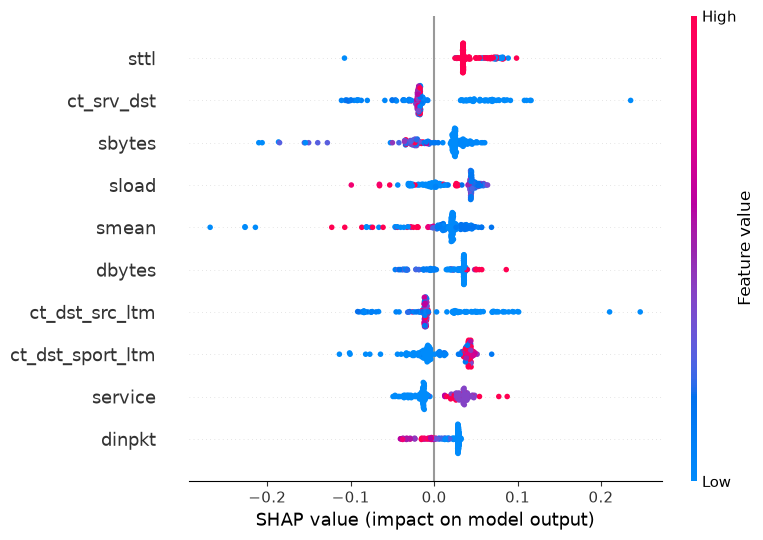

In [2]:
import numpy as np
import pandas as pd
import shap

attaques = X_test[y_test == 1].sample(200, random_state=0)
sv = shap.TreeExplainer(copie).shap_values(attaques)   # sur la COPIE : l'attaquant n'a pas l'IDS
sv = sv[1] if isinstance(sv, list) else sv[..., 1]     # on garde les contributions vers « attaque »

shap.summary_plot(sv, attaques, max_display=10)

**👀 Ce qu'on doit voir :** `sttl` en haut de la liste.

*Comment lire le graphique :* une ligne par feature, un point par attaque. Un point **à droite** pousse vers « attaque », **à gauche** vers « normal ». La couleur donne la valeur de la feature (rouge = élevée, bleu = basse).

## Étape 3 : Ce que l'attaquant peut vraiment changer
**Ce qu'on fait :** on croise le classement SHAP avec la liste des features que l'attaquant contrôle depuis sa machine (taille, nombre de paquets, durée, rythme).

In [3]:
from helper import CONTROLABLES

importance = pd.Series(np.abs(sv).mean(0), index=X_test.columns).sort_values(ascending=False)
top10 = importance.head(10).to_frame('importance SHAP')
top10['contrôlable ?'] = top10.index.isin(CONTROLABLES)
top10

,importance SHAP,contrôlable ?
sttl,0.045477,False
ct_srv_dst,0.037613,False
sbytes,0.033411,True
sload,0.032609,True
smean,0.031347,True
dbytes,0.030473,True
ct_dst_src_ltm,0.028947,False
ct_dst_sport_ltm,0.028863,False
service,0.025989,False
dinpkt,0.023750,False


**👀 Ce qu'on doit voir :** 4 features du top 10 sont contrôlables : `sbytes`, `sload`, `smean`, `dbytes`. Ce sont les cibles de l'attaquant.

La première, `sttl` (le TTL des paquets envoyés), est classée « non contrôlable » dans notre liste. En réalité, **le TTL est fixé par la machine de l'attaquant**. On y revient à l'ex. 5.

**❓ Question pour la classe :** parmi les 10 features les plus importantes, lesquelles sont des cibles idéales pour l'attaquant ?

## Étape 4 : Contre-mesure : le défenseur utilise SHAP avant l'attaquant
**Ce qu'on fait :** `sttl` en tête est un **raccourci** connu de UNSW-NB15 : dans le banc d'essai, les machines attaquantes avaient des TTL particuliers.
Le modèle a appris « TTL bizarre = attaque » au lieu de « comportement malveillant = attaque ». On retire les features TTL et on réentraîne.

In [4]:
# <-- MODIFIABLE : ajoutez ou retirez des features suspectes
raccourcis = ['sttl', 'dttl', 'ct_state_ttl']

from helper import evaluer
ids_sans_ttl = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1).fit(X_train.drop(columns=raccourcis), y_train)

evaluer(ids, X_test, y_test, 'IDS original ')
evaluer(ids_sans_ttl, X_test.drop(columns=raccourcis), y_test, 'IDS sans TTL ')

IDS original  -> accuracy = 0.901 | recall (attaques détectées) = 0.864


IDS sans TTL  -> accuracy = 0.899 | recall (attaques détectées) = 0.863


**👀 Ce qu'on doit voir :** presque aucune perte : accuracy 0,901 → 0,899, recall 0,864 → 0,863.

**❓ Question pour la classe :** le modèle perd très peu. Le raccourci était-il vraiment utile ? (L'ex. 5 montre ce qu'il coûte face à un attaquant.)

## Ce qu'il faut retenir
- SHAP sur une copie dit à l'attaquant **quoi modifier**, sans jamais toucher à l'IDS.
- Les features importantes ne sont pas toutes contrôlables : l'attaquant vise les features importantes **et** contrôlables.
- Le défenseur doit faire cette analyse en premier, pour repérer les raccourcis. Et **ne jamais exposer les explications SHAP** aux utilisateurs d'un système de sécurité.

**Exercice suivant :** savoir quoi modifier, c'est bien. Savoir **vers quoi** aller, c'est mieux : à quoi ressemble un flux normal ?